In [1]:
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
import pathlib
from pathlib import Path
import Sentinel

In [2]:
%matplotlib widget

In [3]:
here = Path('.')

In [4]:
##Paths to each folder
Sent2017 = here/'sentinel-data/S2_2017-07-12'
Sent2018 = here/'sentinel-data/S2_2018-07-12'
Sent2019 = here/'sentinel-data/S2_2019-07-12'

In [5]:
#Obtain file from 
Files2017 = Sentinel.obtain_files("2017", Sent2017)
Files2018 = Sentinel.obtain_files("2018", Sent2018)
Files2019 = Sentinel.obtain_files("2019", Sent2019)

In [6]:
for i, file in enumerate(Files2017):
    print(i, file)

0 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B01_Raw.tiff
1 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B02_Raw.tiff
2 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B03_Raw.tiff
3 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B04_Raw.tiff
4 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B05_Raw.tiff
5 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B06_Raw.tiff
6 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B07_Raw.tiff
7 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B08_Raw.tiff
8 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B09_Raw.tiff
9 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B11_Raw.tiff
10 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B12_Raw.tiff
11 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_B8A_Raw.tiff
12 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_False_color.tiff
13 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_False_color_urban.tiff
14 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_Highlight_Optimized_Natural_Color.tiff
15 sentinel-data\S2_2017-07-12\Sentinel-2_L2A_Moisture_index.tiff
16 sentinel-data\S2

In [7]:
for i, file in enumerate(Files2018):
    print(i, file)

0 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B01_Raw.tiff
1 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B02_Raw.tiff
2 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B03_Raw.tiff
3 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B04_Raw.tiff
4 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B05_Raw.tiff
5 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B06_Raw.tiff
6 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B07_Raw.tiff
7 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B08_Raw.tiff
8 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B09_Raw.tiff
9 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B11_Raw.tiff
10 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B12_Raw.tiff
11 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_B8A_Raw.tiff
12 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_False_color.tiff
13 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_False_color_urban.tiff
14 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_Highlight_Optimized_Natural_Color.tiff
15 sentinel-data\S2_2018-07-12\Sentinel-2_L2A_Moisture_index.tiff
16 sentinel-data\S2

In [8]:
for i, file in enumerate(Files2019):
    print(i, file)

0 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B01_Raw.tiff
1 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B02_Raw.tiff
2 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B03_Raw.tiff
3 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B04_Raw.tiff
4 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B05_Raw.tiff
5 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B06_Raw.tiff
6 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B07_Raw.tiff
7 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B08_Raw.tiff
8 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B09_Raw.tiff
9 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B11_Raw.tiff
10 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B12_Raw.tiff
11 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B8A_Raw.tiff
12 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_False_color.tiff
13 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_False_color_urban.tiff
14 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_Highlight_Optimized_Natural_Color.tiff
15 sentinel-data\S2_2019-07-12\Sentinel-2_L2A_Moisture_index.tiff
16 sentinel-data\S2

In [9]:
#Read the data inside the file required for processing and analysis of the vegetation
NDVI7= Sentinel.readata(Files2017, 17)
B8_7= Sentinel.readata(Files2017, 7)
B4_7= Sentinel.readata(Files2017, 3)

NDVI8= Sentinel.readata(Files2018, 17)
B8_8= Sentinel.readata(Files2018, 7)
B4_8= Sentinel.readata(Files2018, 3)

NDVI9= Sentinel.readata(Files2019, 17)
B8_9= Sentinel.readata(Files2019, 7)
B4_9= Sentinel.readata(Files2019, 3)


In [10]:
#Compute the vegetation image for each year
vegetation17 = Sentinel.veggie(B8_7,B4_7)
vegetation18 = Sentinel.veggie(B8_8,B4_8)
vegetation19 = Sentinel.veggie(B8_9,B4_9)

In [11]:
vegetation17

array([[-0.43661973, -0.37837836, -0.16883115, ...,  0.        ,
         0.        ,  0.        ],
       [-0.42105263, -0.27272722, -0.05882354, ...,  0.        ,
         0.        ,  0.        ],
       [-0.2658228 , -0.23943661, -0.2238806 , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.27710843,
        -0.15492958, -0.4054054 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.45161292,
        -0.30434778, -0.2280702 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.4098361 ,
        -0.3947368 , -0.32307693]], shape=(314, 529), dtype=float32)

In [12]:
vegetation18

array([[-0.0888889 , -0.07142857, -0.14102565, ...,  0.        ,
         0.        ,  0.        ],
       [-0.04918034, -0.03896106, -0.07096774, ...,  0.        ,
         0.        ,  0.        ],
       [-0.01980199, -0.02352943, -0.05142859, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.3015873 ,
        -0.13821141, -0.11450384],
       [ 0.        ,  0.        ,  0.        , ..., -0.09375001,
        -0.08148148, -0.07042255],
       [ 0.        ,  0.        ,  0.        , ..., -0.12258065,
        -0.02068965, -0.03797468]], shape=(314, 529), dtype=float32)

In [13]:
vegetation19

array([[-0.09941521, -0.10112359, -0.11999998, ...,  0.        ,
         0.        ,  0.        ],
       [-0.02469137, -0.10843375, -0.06185566, ...,  0.        ,
         0.        ,  0.        ],
       [-0.0322581 , -0.14473684, -0.1446541 , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.12437812,
        -0.10869567, -0.1446541 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.0340909 ,
        -0.10303032, -0.18120806],
       [ 0.        ,  0.        ,  0.        , ..., -0.09459462,
        -0.26896554, -0.14728682]], shape=(314, 529), dtype=float32)

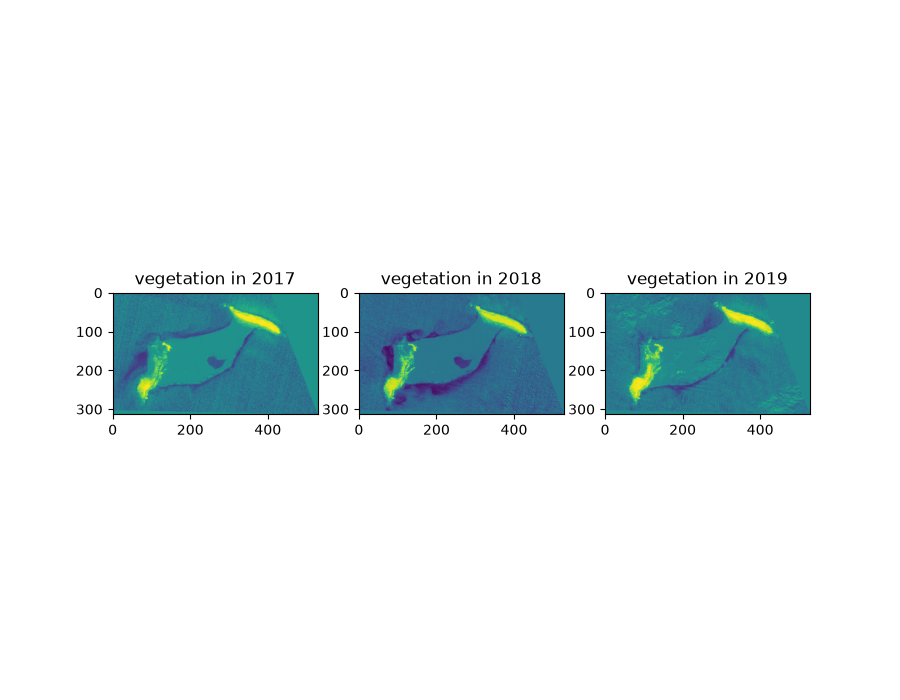

In [14]:
plt.close('all')
#Plot the vegetation image as a function of time
fog,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(9,7))

show(vegetation17, ax=ax1)
show(vegetation18, ax=ax2)
show(vegetation19, ax=ax3)

ax1.set_title("vegetation in 2017")
ax2.set_title("vegetation in 2018")
ax3.set_title("vegetation in 2019")

plt.show()

In [17]:
#Calculate pixel area
with rasterio.open(Files2019[9]) as src:
    
    #Extract angular pixel resolution 
    res_x, res_y = src.res  
    
    #Extract image bounding box coordinates
    left, bottom, right, top = src.bounds
    
#Calculate center latitude in radians
center_lat_deg = (bottom + top) / 2.0
center_lat_rad = np.radians(center_lat_deg)
meters_per_deg_lat = 111320.0
#Calculate center longitude in radians
meters_per_deg_lon = 111320.0 * np.cos(center_lat_rad)
#Calculate width and height
pixel_width_m = res_x * meters_per_deg_lon
pixel_height_m = res_y * meters_per_deg_lat
#Calculate pixel size
pixelarea = pixel_width_m * pixel_height_m


In [18]:
#Calculate the area covered with vegetation
VegetationArea2017 = Sentinel.calculate_veggie_area(vegetation17,pixelarea)
VegetationArea2018 = Sentinel.calculate_veggie_area(vegetation18,pixelarea)
VegetationArea2019 = Sentinel.calculate_veggie_area(vegetation19,pixelarea)

In [19]:
print(f"The area covered in vegetation was {VegetationArea2017}m^2 in 2017")
print(f"The area covered in vegetation was {VegetationArea2018}m^2 in 2018")
print(f"The area covered in vegetation was {VegetationArea2019}m^2 in 2019")

The area covered in vegetation was 429531.1096004942m^2 in 2017
The area covered in vegetation was 523071.4901590492m^2 in 2018
The area covered in vegetation was 566068.4755940323m^2 in 2019


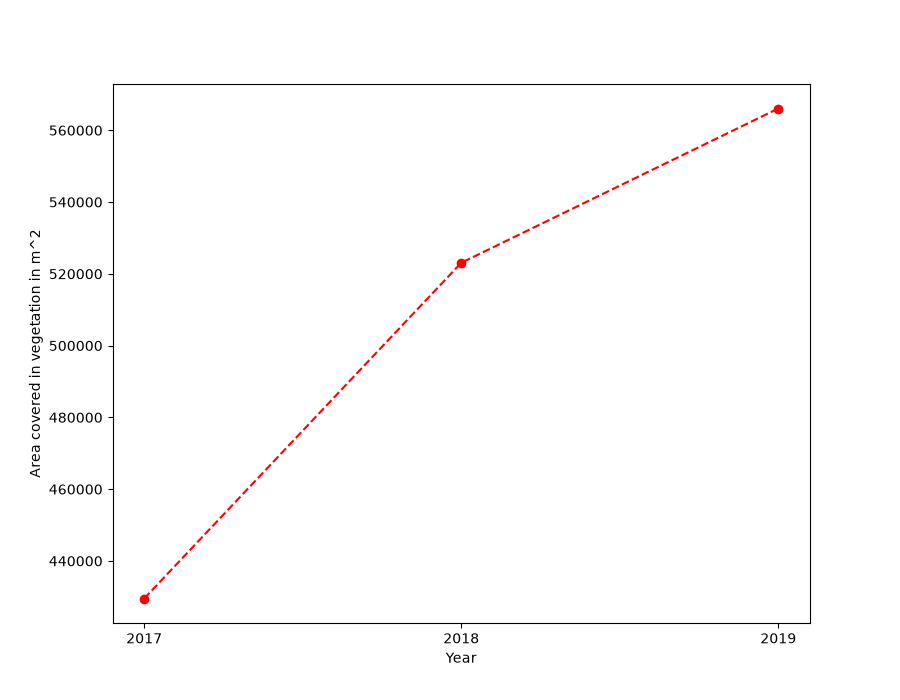

In [20]:
#Make a plot of the area covered in vegetation as a function of time
fig,ax = plt.subplots(figsize=(9,7))
xpoints = np.array(["2017", "2018", "2019"])
ypoints = np.array([VegetationArea2017, VegetationArea2018, VegetationArea2019])

plt.scatter(xpoints, ypoints, color = 'red')
plt.plot(xpoints, ypoints, color= 'red', linestyle='--')
plt.xlabel("Year")
plt.ylabel("Area covered in vegetation in m^2")
plt.show()

Text(0.5, 1.0, 'vegetation mask in 2019')

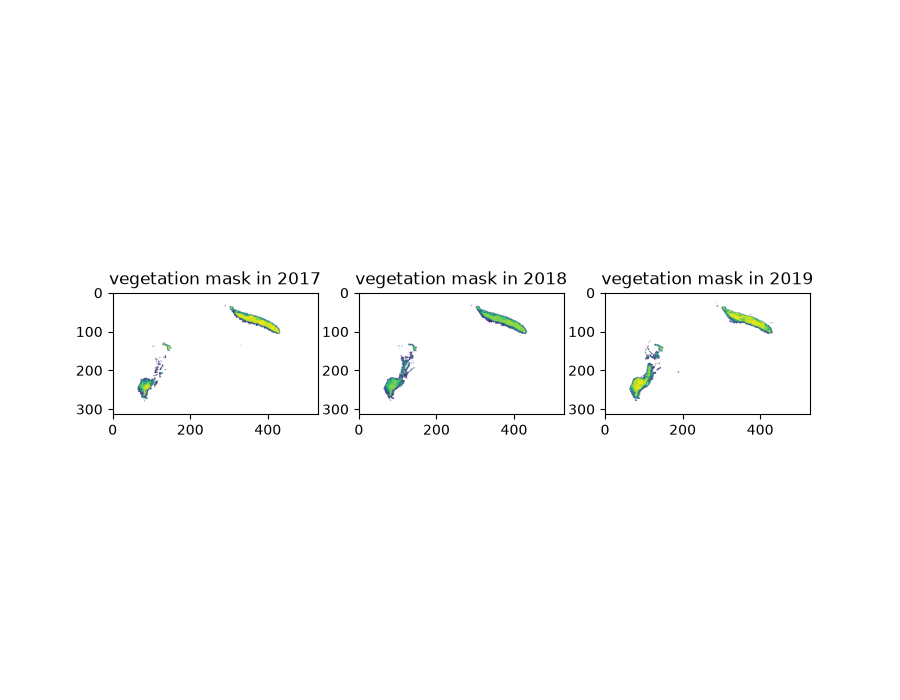

In [22]:
plt.close('all')
#Plot the mask used to just obtain the vegetation from the image
fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(9,7))

mask17 = vegetation17<0.45
mask18 = vegetation18<0.45
mask19 = vegetation19<0.45

vegetation_masked17 = np.ma.masked_array(vegetation17, mask=mask17)
vegetation_masked18 = np.ma.masked_array(vegetation18, mask=mask18)
vegetation_masked19 = np.ma.masked_array(vegetation19, mask=mask19)

show(vegetation_masked17, ax=ax1)
show(vegetation_masked18, ax=ax2)
show(vegetation_masked19, ax=ax3)

ax1.set_title("vegetation mask in 2017")
ax2.set_title("vegetation mask in 2018")
ax3.set_title("vegetation mask in 2019")

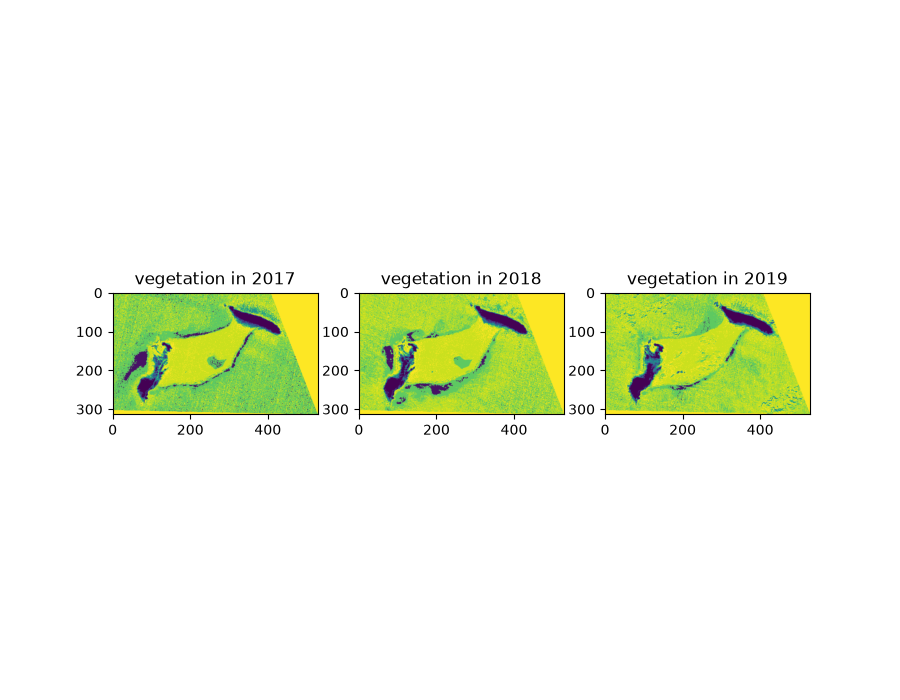

In [24]:
plt.close('all')
#plot the vegetation image provided from sentinel-2
fog,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(9,7))

show(NDVI7, ax=ax1)
show(NDVI8, ax=ax2)
show(NDVI9, ax=ax3)


ax1.set_title("vegetation in 2017")
ax2.set_title("vegetation in 2018")
ax3.set_title("vegetation in 2019")

plt.show()

In [25]:
#Compute some statistics from both the vegetation image provided from sentinel-2 and the computed vegetation to produce a quantitative comparition - 2017
stats_computedveg_2017 = Sentinel.comparition_stats(vegetation17)
stats_providedveg_2017 = Sentinel.comparition_stats(NDVI7)


print("-" * 27)
print(" Statistics for vegetation computed in 2017     ")
print("-" * 27)

for key, value in stats_computedveg_2017.items():
  print(f" {key:<9} : {value:>9.4f} ")

print("-" * 27)

print("-" * 27)
print(" Statistics for vegetation provided in 2017  ")
print("-" * 27)

# Loop through and print each row with vertical bars (|)
for key, value in stats_providedveg_2017.items():
  print(f" {key:<9} : {value:>9.4f} ")

print("-" * 27)


---------------------------
 Statistics for vegetation computed in 2017     
---------------------------
 Mean      :   -0.1269 
 Median    :   -0.1461 
 Std Dev   :    0.2242 
 Min       :   -1.0000 
 Max       :    0.9323 
---------------------------
---------------------------
 Statistics for vegetation provided in 2017  
---------------------------
 Mean      :    0.7989 
 Median    :    0.8600 
 Std Dev   :    0.2162 
 Min       :    0.0000 
 Max       :    1.0000 
---------------------------


In [26]:
#Compute some statistics from both the vegetation image provided from sentinel and the computed vegetation to produce a quantitative comparition - 2018
stats_computedveg_2018 = Sentinel.comparition_stats(vegetation18)
stats_providedveg_2018 = Sentinel.comparition_stats(NDVI8)


print("-" * 27)
print(" Statistics for vegetation computed in 2018     ")
print("-" * 27)


for key, value in stats_computedveg_2018.items():
  print(f" {key:<9} : {value:>9.4f} ")

print("-" * 27)

print("-" * 27)
print(" Statistics for vegetation provided in 2018  ")
print("-" * 27)


for key, value in stats_providedveg_2018.items():
  print(f" {key:<9} : {value:>9.4f} ")

print("-" * 27)

print("Correlation between both: ")


---------------------------
 Statistics for vegetation computed in 2018     
---------------------------
 Mean      :   -0.0683 
 Median    :   -0.0667 
 Std Dev   :    0.2079 
 Min       :   -0.6871 
 Max       :    1.0000 
---------------------------
---------------------------
 Statistics for vegetation provided in 2018  
---------------------------
 Mean      :    0.8327 
 Median    :    0.9200 
 Std Dev   :    0.2170 
 Min       :    0.0000 
 Max       :    1.0000 
---------------------------
Correlation between both: 


In [27]:
#Compute some statistics from both the vegetation image provided from sentinel and the computed vegetation to produce a quantitative comparition - 2019
stats_computedveg_2019 = Sentinel.comparition_stats(vegetation19)
stats_providedveg_2019 = Sentinel.comparition_stats(NDVI9)


print("-" * 27)
print(" Statistics for vegetation computed in 2019     ")
print("-" * 27)


for key, value in stats_computedveg_2019.items():
  print(f" {key:<9} : {value:>9.4f} ")

print("-" * 27)

print("-" * 27)
print(" Statistics for vegetation provided in 2019 ")
print("-" * 27)


for key, value in stats_providedveg_2019.items():
  print(f" {key:<9} : {value:>9.4f} ")

print("-" * 27)


---------------------------
 Statistics for vegetation computed in 2019     
---------------------------
 Mean      :   -0.0455 
 Median    :   -0.0575 
 Std Dev   :    0.2028 
 Min       :   -0.8493 
 Max       :    0.9324 
---------------------------
---------------------------
 Statistics for vegetation provided in 2019 
---------------------------
 Mean      :    0.8403 
 Median    :    0.9200 
 Std Dev   :    0.2042 
 Min       :    0.0000 
 Max       :    1.0000 
---------------------------


In [28]:
here = Path('.')
#obtain the white images from Google Earth
white_images = sorted(list((here / 'sentinel-data/White_light').glob('*.jpg')))
for im in white_images:
    print(im)

sentinel-data\White_light\2014Feb.jpg
sentinel-data\White_light\2016May.jpg
sentinel-data\White_light\2020Nov.jpg
sentinel-data\White_light\2021Dec.jpg
sentinel-data\White_light\2022Jan.jpg
sentinel-data\White_light\2023Oct.jpg


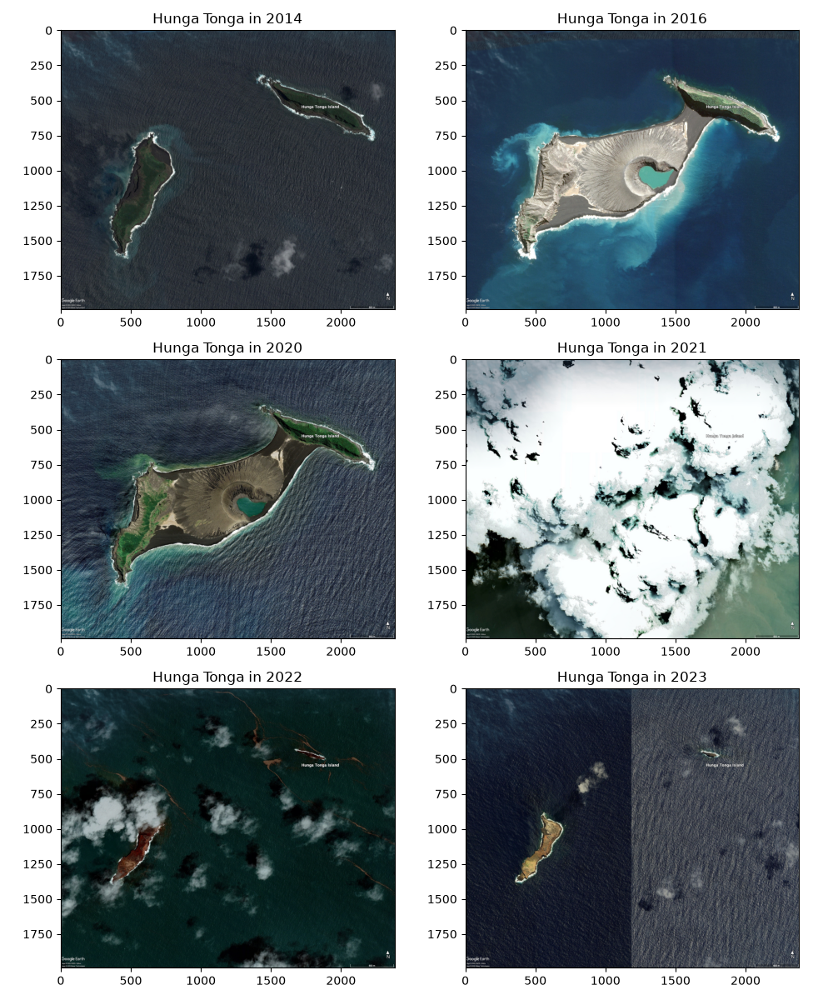

In [30]:
plt.close('all')
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 12), tight_layout=True)
axes = axes.ravel()

#Plot the images from Hunga Tonga as a function of time
titles = ["Hunga Tonga in 2014", "Hunga Tonga in 2016", "Hunga Tonga in 2020", "Hunga Tonga in 2021", "Hunga Tonga in 2022", "Hunga Tonga in 2023"]
for i, ax in enumerate(axes):
    img = mpimg.imread(white_images[i])
    ax.imshow(img)
    ax.set_title(titles[i])

In [32]:
#converts rgb(red, green, blue) image array into hsv image array(hue, saturation, value)
hsv_image2014, rgb_image2014 = Sentinel.hsv_image(white_images[0])
hsv_image2016, rgb_image2016 = Sentinel.hsv_image(white_images[1])
hsv_image2020, rgb_image2020 = Sentinel.hsv_image(white_images[2])
hsv_image2021, rgb_image2021 = Sentinel.hsv_image(white_images[3])
hsv_image2022, rgb_image2022 = Sentinel.hsv_image(white_images[4])
hsv_image2023, rgb_image2023 = Sentinel.hsv_image(white_images[5])

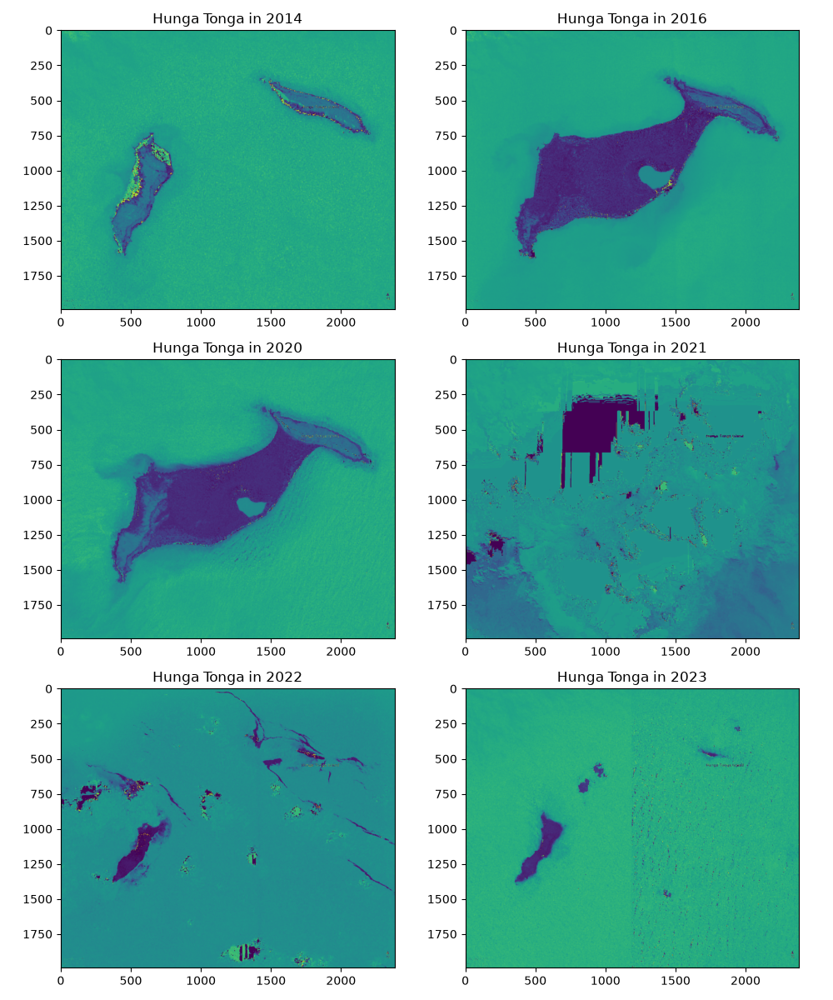

In [37]:
#plot the hsv images from Hunga Tonga as a function of time
plt.close('all')
fig, ((ax, ax1), (ax2, ax3), (ax4, ax5)) = plt.subplots(
    nrows=3, ncols=2, figsize=(10, 12), tight_layout=True
)

ax.imshow(hsv_image2014[:, :, 0])
ax.set_title("Hunga Tonga in 2014")

ax1.imshow(hsv_image2016[:, :, 0])
ax1.set_title("Hunga Tonga in 2016")

ax2.imshow(hsv_image2020[:, :, 0])
ax2.set_title("Hunga Tonga in 2020")

ax3.imshow(hsv_image2021[:, :, 0])
ax3.set_title("Hunga Tonga in 2021")

ax4.imshow(hsv_image2022[:, :, 0])
ax4.set_title("Hunga Tonga in 2022")

ax5.imshow(hsv_image2023[:, :, 0])
ax5.set_title("Hunga Tonga in 2023")


plt.show()

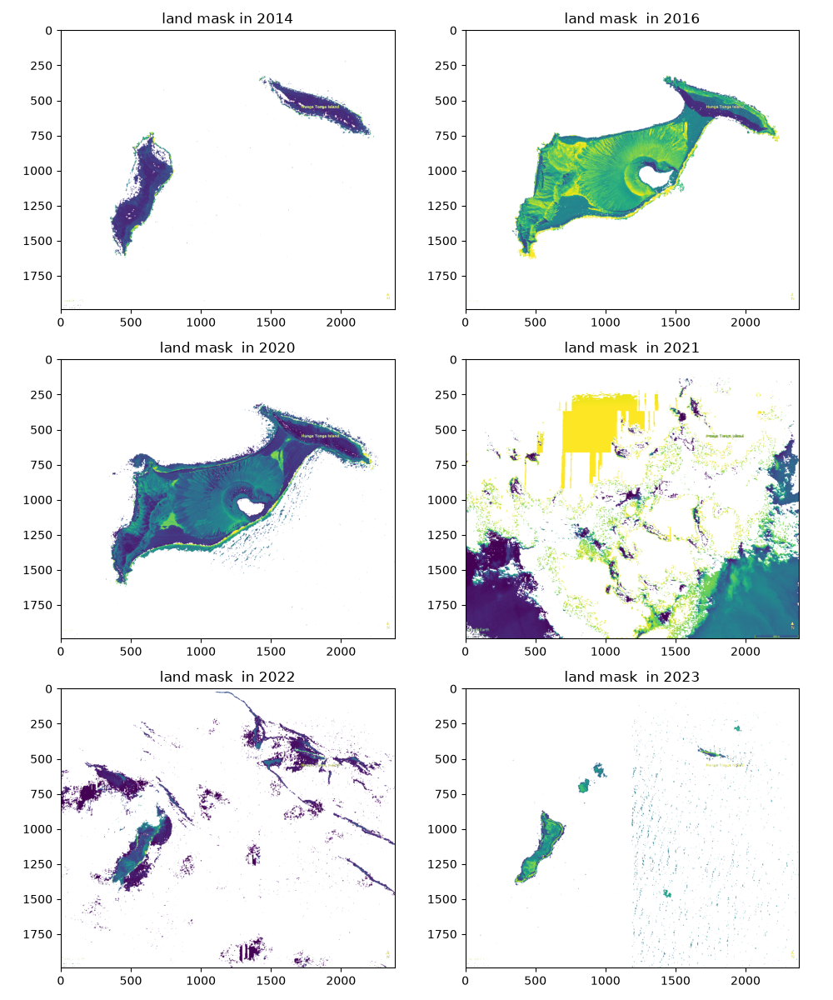

In [36]:
#Mask the images to obtain only the land area and plot
plt.close('all')
fig, ((ax, ax1), (ax2, ax3), (ax4, ax5)) = plt.subplots(
    nrows=3, ncols=2, figsize=(10, 12), tight_layout=True
)

land_mask = hsv_image2014[:, :, 0]>0.45
ax.imshow(np.ma.masked_array(rgb_image2014[...,0], mask=land_mask))
ax.set_title("land mask in 2014")

land_mask1 = hsv_image2016[:, :, 0]>0.45
ax1.imshow(np.ma.masked_array(rgb_image2016[...,0], mask=land_mask1))
ax1.set_title("land mask  in 2016")

land_mask2 = hsv_image2020[:, :, 0]>0.45
ax2.imshow(np.ma.masked_array(rgb_image2020[...,0], mask=land_mask2))
ax2.set_title("land mask  in 2020")

land_mask3 = hsv_image2021[:, :, 0]>0.45
ax3.imshow(np.ma.masked_array(rgb_image2021[...,0], mask=land_mask3))
ax3.set_title("land mask  in 2021")

land_mask4 = hsv_image2022[:, :, 0]>0.45
ax4.imshow(np.ma.masked_array(rgb_image2022[...,0], mask=land_mask4))
ax4.set_title("land mask  in 2022")

land_mask5 = hsv_image2023[:, :, 0]>0.45
ax5.imshow(np.ma.masked_array(rgb_image2023[...,0], mask=land_mask5))
ax5.set_title("land mask  in 2023")


plt.show()

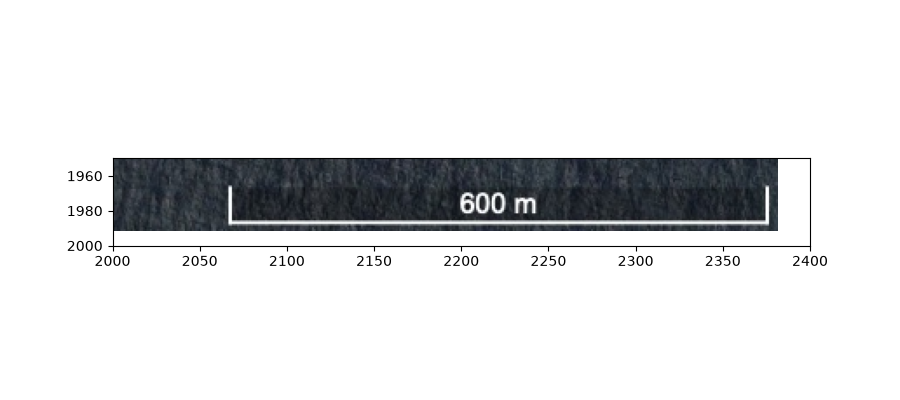

In [38]:
#zoom into the scale bar to obtain information about the pixel size
wl = mpimg.imread(white_images[0])
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(wl)
ax.set_xlim(2000,2400)
ax.set_ylim(2000, 1950)
plt.show()

In [39]:
#Based on the scale bar provided from Google Earth images, calculate the pixel size (using the x-axis values)
pixels = 2375 - 2062
size = 600 / pixels
area_pixel = size*size
area_pixel

3.674631771274587

In [41]:
#Calculate the land area of Hunga Tonga at different years
land_area_2014 = Sentinel.calculate_land_area(hsv_image2014[:, :, 0], area_pixel)
land_area_2016 = Sentinel.calculate_land_area(hsv_image2016[:, :, 0], area_pixel)
land_area_2020 = Sentinel.calculate_land_area(hsv_image2020[:, :, 0], area_pixel)
land_area_2021 = Sentinel.calculate_land_area(hsv_image2021[:, :, 0], area_pixel)
land_area_2022 = Sentinel.calculate_land_area(hsv_image2022[:, :, 0], area_pixel)
land_area_2023 = Sentinel.calculate_land_area(hsv_image2023[:, :, 0], area_pixel)

print(f"Land area of Hunga Tonga in 2014: {land_area_2014}m^2" )
print(f"Land area of Hunga Tonga in 2016: {land_area_2016}m^2" )
print(f"Land area of Hunga Tonga in 2020: {land_area_2020}m^2" )
print(f"Land area of Hunga Tonga in 2021: {land_area_2021}m^2. However, it is not correct because of the high ammount of clouds " )
print(f"Land area of Hunga Tonga in 2022: {land_area_2022}m^2. Also inaccurate, but better" )
print(f"Land area of Hunga Tonga in 2023: {land_area_2023}m^2" )

Land area of Hunga Tonga in 2014: 859121.5588604559m^2
Land area of Hunga Tonga in 2016: 2924808.4598189224m^2
Land area of Hunga Tonga in 2020: 3176153.272974104m^2
Land area of Hunga Tonga in 2021: 5032896.936786126m^2. However, it is not correct because of the high ammount of clouds 
Land area of Hunga Tonga in 2022: 1346385.0809950088m^2. Also inaccurate, but better
Land area of Hunga Tonga in 2023: 397547.3874388838m^2


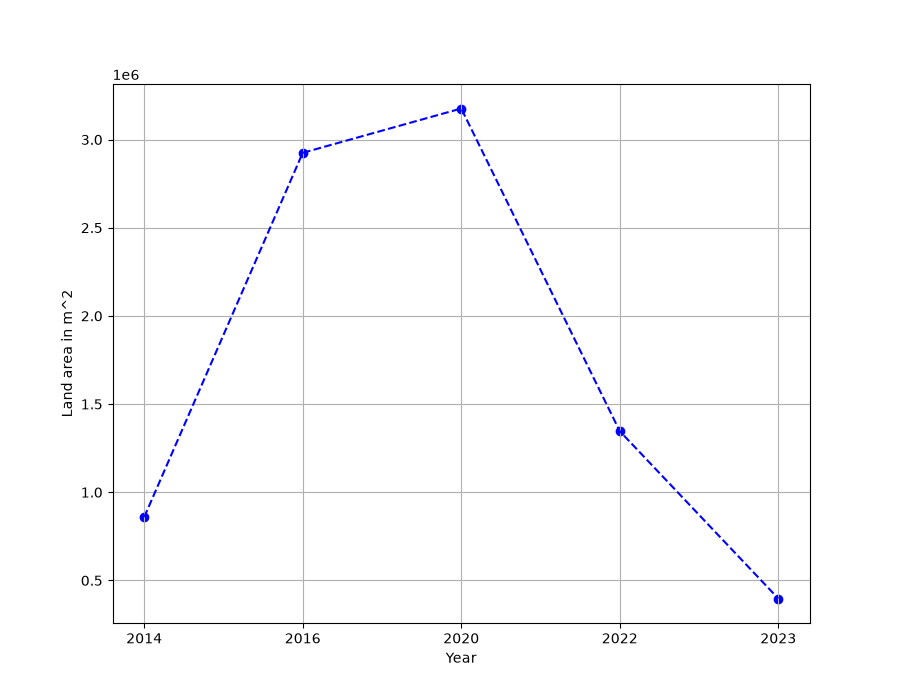

In [42]:
#Plot the land area of Hunga Tonga as a function of time
fig,ax = plt.subplots(figsize=(9,7))
xpoints = np.array(["2014", "2016", "2020","2022","2023"]) # year 2021 is removed because of its inaccuracy
ypoints = np.array([land_area_2014, land_area_2016, land_area_2020,land_area_2022,land_area_2023])

plt.scatter(xpoints, ypoints, color = 'blue')
plt.plot(xpoints, ypoints, color= 'blue', linestyle='--')
plt.xlabel("Year")
plt.ylabel("Land area in m^2")
plt.grid()
plt.show()